# Laboratório — LSTM aplicada à classificação de textos

# Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


# 1. Dataset: textos e classes

Cada avaliação é uma instância. **1 = positiva; 0 = negativa.** Separaremos treinamento, validação e teste, mantendo as duas classes em cada conjunto.


In [2]:
# Criar um pequeno dataset didático de avaliações de produtos.
# Cada texto é uma instância e a classe indica:
# 1 = avaliação positiva
# 0 = avaliação negativa

positivos = [
    "produto muito bom",
    "gostei muito do produto",
    "qualidade excelente e acabamento bom",
    "produto funciona muito bem",
    "compra valeu a pena",
    "produto chegou perfeito",
    "material de boa qualidade",
    "produto superou minhas expectativas",
    "estou satisfeito com a compra",
    "recomendo este produto",
    "produto bonito e confortável",
    "ótimo produto para o preço",
    "funcionou perfeitamente",
    "produto fácil de usar",
    "boa qualidade e bom acabamento",
    "não tive problemas com o produto",
    "produto chegou rápido e funcionando",
    "gostei do acabamento",
    "vale muito a pena",
    "produto excelente",
    "muito satisfeito com o produto",
    "compra muito boa",
    "produto atende bem",
    "recomendo a compra"
]

negativos = [
    "produto muito ruim",
    "não gostei do produto",
    "qualidade péssima e acabamento ruim",
    "produto não funciona bem",
    "compra não valeu a pena",
    "produto chegou quebrado",
    "material de baixa qualidade",
    "produto ficou abaixo das expectativas",
    "estou insatisfeito com a compra",
    "não recomendo este produto",
    "produto desconfortável e frágil",
    "péssimo produto para o preço",
    "não funcionou corretamente",
    "produto difícil de usar",
    "baixa qualidade e acabamento ruim",
    "tive muitos problemas com o produto",
    "produto chegou com defeito",
    "não gostei do acabamento",
    "não vale a pena",
    "produto péssimo",
    "muito insatisfeito com o produto",
    "compra muito ruim",
    "produto não atende bem",
    "não recomendo a compra"
]

textos = np.array(positivos + negativos)
rotulos = np.array([1] * len(positivos) + [0] * len(negativos))

# Em cada classe: 16 textos para treino, 4 para validação e 4 para teste.
# Cada texto aparece em apenas um conjunto.
rng = np.random.default_rng(42)
idx_treino, idx_val, idx_teste = [], [], []
for classe in [0, 1]:
    idx = rng.permutation(np.flatnonzero(rotulos == classe))
    idx_treino.extend(idx[:16])
    idx_val.extend(idx[16:20])
    idx_teste.extend(idx[20:])

idx_treino = rng.permutation(idx_treino)
idx_val = rng.permutation(idx_val)
idx_teste = rng.permutation(idx_teste)
textos_treino, y_train = textos[idx_treino], rotulos[idx_treino]
textos_val, y_val = textos[idx_val], rotulos[idx_val]
textos_teste, y_test = textos[idx_teste], rotulos[idx_teste]

for nome, ids in [("Treino", idx_treino), ("Validação", idx_val), ("Teste", idx_teste)]:
    print(f"{nome}: {len(ids)} textos | negativas/positivas: {np.bincount(rotulos[ids])}")
print("\nExemplos do treinamento:")
for texto, classe in zip(textos_treino[:5], y_train[:5]):
    print(f"{classe} -> {texto}")


Treino: 32 textos | negativas/positivas: [16 16]
Validação: 8 textos | negativas/positivas: [4 4]
Teste: 8 textos | negativas/positivas: [4 4]

Exemplos do treinamento:
1 -> produto chegou perfeito
0 -> produto chegou com defeito
1 -> material de boa qualidade
1 -> compra muito boa
0 -> não gostei do acabamento


## Perguntas

**1.** O que representam as entradas e os rótulos deste problema supervisionado?  
**2.** Por que os mesmos conjuntos de treinamento, validação e teste devem ser usados na comparação entre RNN e LSTM?


# 2. Tokenização e timesteps

O texto é convertido em uma sequência de **IDs de tokens**. Cada ID ainda é um número identificador, não o vetor que entrará na LSTM. `T = 10` fixa o tamanho da sequência: textos curtos recebem padding e textos longos são truncados.


In [3]:
T = 10

vectorizador = layers.TextVectorization(
    max_tokens=200, output_mode="int", output_sequence_length=T
)
# Aprender o vocabulário apenas com o treinamento.
vectorizador.adapt(textos_treino)
X_train = vectorizador(textos_treino).numpy()
X_val = vectorizador(textos_val).numpy()
X_test = vectorizador(textos_teste).numpy()
vocabulario = vectorizador.get_vocabulary()
V = len(vocabulario)

print("Vocabulário:", V, "entradas | 0 = padding; 1 = token desconhecido")
print("Shape de treino:", X_train.shape)

exemplos = np.array([
    "produto excelente",
    "produto muito bom e fácil de usar e chegou rápido funcionando perfeitamente"
])
for texto, ids in zip(exemplos, vectorizador(exemplos).numpy()):
    tokens_validos = [vocabulario[int(i)] for i in ids if i != 0]
    print("\nTexto:", texto)
    print("IDs:", ids)
    print("Tokens mantidos:", tokens_validos)


Vocabulário: 55 entradas | 0 = padding; 1 = token desconhecido
Shape de treino: (32, 10)

Texto: produto excelente
IDs: [ 2 46  0  0  0  0  0  0  0  0]
Tokens mantidos: [np.str_('produto'), np.str_('excelente')]

Texto: produto muito bom e fácil de usar e chegou rápido funcionando perfeitamente
IDs: [ 2  4 26 13  1 25  1 13 10 33]
Tokens mantidos: [np.str_('produto'), np.str_('muito'), np.str_('bom'), np.str_('e'), '[UNK]', np.str_('de'), '[UNK]', np.str_('e'), np.str_('chegou'), np.str_('rápido')]


## Perguntas

**3.** O que `T = 10` representa? Esse valor é a dimensão de cada vetor de token?  
**4.** Identifique padding e truncamento nos exemplos. Por que eles são operações sobre o comprimento da sequência?


# 3. Embedding: um vetor para cada token

O Embedding transforma cada ID em um vetor **vₜ de dimensão d**. Usaremos `d = 4`, independentemente da quantidade de neurônios da LSTM. `mask_zero=True` indica que os passos de padding devem ser ignorados pela camada recorrente.

Aqui os vetores ainda estão inicializados aleatoriamente; nos classificadores, serão aprendidos junto com os demais parâmetros.


In [4]:
d = 4
H = 8

embedding_demo = layers.Embedding(input_dim=V, output_dim=d, mask_zero=True)
amostra_ids = X_train[:2]
vetores_demo = embedding_demo(amostra_ids)
mascara_demo = embedding_demo.compute_mask(amostra_ids)

print("IDs:", amostra_ids.shape)
print("Vetores:", vetores_demo.shape, "= (documentos, T, d)")
print("Máscara do primeiro documento:", mascara_demo[0].numpy())
print("Vetor do primeiro token:", np.round(vetores_demo[0, 0].numpy(), 3))


IDs: (2, 10)
Vetores: (2, 10, 4) = (documentos, T, d)
Máscara do primeiro documento: [ True  True  True False False False False False False False]
Vetor do primeiro token: [ 0.002  0.013 -0.041 -0.005]


## Perguntas

**5.** Interprete o shape `(2, 10, 4)`. Quantos vetores há por documento e quantos componentes há em cada vetor?  
**6.** Qual é a diferença entre `d = 4` e `H = 8`? O que o valor `False` na máscara indica?


# 4. LSTM: estado oculto h e memória c

A LSTM recebe vₜ e os estados anteriores hₜ₋₁ e cₜ₋₁. Cada passo produz novos hₜ e cₜ. `return_sequences=True` devolve todos os estados ocultos; `return_state=True` devolve também os estados finais h e c.

A demonstração abaixo ainda **não foi treinada**: serve para observar os formatos e as operações, não para interpretar importância das palavras.


In [5]:
lstm_demo = layers.LSTM(H, return_sequences=True, return_state=True)
sequencia_h, h_final_demo, c_final_demo = lstm_demo(
    vetores_demo, mask=mascara_demo
)

print("Sequência de h:", sequencia_h.shape)
print("h final:", h_final_demo.shape)
print("c final:", c_final_demo.shape)
print("\nh do primeiro documento:", np.round(h_final_demo[0].numpy(), 3))
print("c do primeiro documento:", np.round(c_final_demo[0].numpy(), 3))


Sequência de h: (2, 10, 8)
h final: (2, 8)
c final: (2, 8)

h do primeiro documento: [-0.004 -0.    -0.001  0.    -0.006 -0.003  0.001 -0.008]
c do primeiro documento: [-0.008 -0.    -0.002  0.001 -0.012 -0.005  0.002 -0.016]


### Observe os cálculos de um passo

Vamos acompanhar os dois primeiros tokens do primeiro documento. Os cálculos abaixo usam **os pesos da mesma LSTM acima**. Em cada passo, a camada produz oito valores para cada porta e para a candidata; para facilitar a leitura, imprimiremos apenas o **neurônio 1**.

No Keras, os quatro conjuntos estão reunidos nas matrizes, na ordem **i, f, g, o**. A divisão em quatro partes apenas separa esses conjuntos; não cria novos pesos.


In [6]:
W, U, b = lstm_demo.get_weights()

def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))

h_anterior = np.zeros(H, dtype=np.float32)
c_anterior = np.zeros(H, dtype=np.float32)
print("Valores do neurônio 1 (pesos ainda não treinados):")
for t in range(2):
    v = vetores_demo[0, t].numpy()
    # As multiplicações abaixo usam a disposição de matrizes do Keras.
    z = v @ W + h_anterior @ U + b
    z_i, z_f, z_g, z_o = np.split(z, 4)
    i = sigmoide(z_i)
    f = sigmoide(z_f)
    g = np.tanh(z_g)
    o = sigmoide(z_o)
    memoria_preservada = f * c_anterior
    informacao_nova = i * g
    c_atual = memoria_preservada + informacao_nova
    h_atual = o * np.tanh(c_atual)
    token = vocabulario[int(amostra_ids[0, t])]
    print(f"\nPasso {t + 1} | token: {token}")
    print(f"f={f[0]:.4f} | i={i[0]:.4f} | g={g[0]:.4f} | o={o[0]:.4f}")
    print(f"c = {memoria_preservada[0]:.4f} + {informacao_nova[0]:.4f} = {c_atual[0]:.4f}")
    print(f"h = {o[0]:.4f} × tanh({c_atual[0]:.4f}) = {h_atual[0]:.4f}")
    h_anterior, c_anterior = h_atual, c_atual


Valores do neurônio 1 (pesos ainda não treinados):

Passo 1 | token: produto
f=0.7326 | i=0.5005 | g=-0.0091 | o=0.4998
c = 0.0000 + -0.0046 = -0.0046
h = 0.4998 × tanh(-0.0046) = -0.0023

Passo 2 | token: chegou
f=0.7343 | i=0.4954 | g=-0.0133 | o=0.4973
c = -0.0034 + -0.0066 = -0.0100
h = 0.4973 × tanh(-0.0100) = -0.0050


## Perguntas

**7.** Por que h e c têm oito componentes, embora vₜ tenha quatro? Qual é a função de cada estado?  
**8.** No cálculo de c, sobre quais informações atuam f e i? Qual é a diferença entre i e g?  
**9.** Se, em um neurônio, f estiver próximo de 1 e i próximo de 0 durante vários passos, o que tende a acontecer com sua memória?


# 5. Classificadores e quantidade de parâmetros

Construiremos **Embedding → camada recorrente → Dense**. Os modelos diferem apenas no tipo da camada recorrente. Ambos usam `d = 4`, `H = 8` e uma saída sigmoide para a classificação binária. A saída recebe **o último h**, não c nem a concatenação dos dez passos.

Na LSTM padrão deste laboratório, c não adiciona uma matriz de pesos própria. A contagem é **4 × H × (d + H + 1)**. O fator 4 corresponde às três portas e à candidata.


In [7]:
def criar_modelo(tipo):
    keras.utils.set_random_seed(42)
    entrada = keras.Input(shape=(T,), dtype="int64", name="entrada")
    emb = layers.Embedding(V, d, mask_zero=True, name="embedding")
    vetores = emb(entrada)
    if tipo == "LSTM":
        recorrente = layers.LSTM(H, return_state=True, name="recorrente")
        _, h_final, c_final = recorrente(vetores)
        estados = keras.Model(entrada, [h_final, c_final])
    else:
        recorrente = layers.SimpleRNN(H, name="recorrente")
        h_final = recorrente(vetores)
        estados = None
    saida = layers.Dense(1, activation="sigmoid", name="saida")(h_final)
    modelo = keras.Model(entrada, saida, name=tipo)
    # Mesmos embeddings iniciais para os dois modelos; ambos serão treinados.
    emb.set_weights(embedding_demo.get_weights())
    return modelo, estados

modelo_lstm, modelo_estados = criar_modelo("LSTM")
modelo_rnn, _ = criar_modelo("RNN")
modelo_lstm.summary()

W, U, b = modelo_lstm.get_layer("recorrente").get_weights()
print("\nParâmetros reunidos da LSTM:")
print("kernel (entrada):", W.shape)
print("recurrent_kernel:", U.shape)
print("bias:", b.shape)

entrada_lstm = d * H * 4
recorrencia_lstm = H * H * 4
biases_lstm = H * 4
print(f"\nEntrada: {d} × {H} × 4 = {entrada_lstm}")
print(f"Recorrência: {H} × {H} × 4 = {recorrencia_lstm}")
print(f"Biases: {H} × 4 = {biases_lstm}")
print("Total LSTM:", entrada_lstm + recorrencia_lstm + biases_lstm)
print("Total RNN:", modelo_rnn.get_layer("recorrente").count_params())
print("\nParâmetros por camada:")
for nome, modelo in [("RNN", modelo_rnn), ("LSTM", modelo_lstm)]:
    print(nome, {camada.name: camada.count_params() for camada in modelo.layers})
    print("Total do classificador:", modelo.count_params())

# T pode mudar sem alterar a quantidade de parâmetros da camada.
outra_lstm = layers.LSTM(H)
outra_lstm.build((None, 20, d))
print("\nLSTM com T=20:", outra_lstm.count_params(), "parâmetros")


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada             │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 10, 4)     │        220 │ entrada[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 10)        │          0 │ entrada[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ recorrente (LSTM)   │ [(None, 8),       │        416 │ embedding[0][0],  │
│                     │ (None, 8), (None, │            │ not_equal[0][0]   │
│                     │ 8)]               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ saida (Dense)       │ (None, 1)         │          9 │ recorrente[0][1]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 645 (2.52 KB)

 Trainable params: 645 (2.52 KB)

 Non-trainable params: 0 (0.00 B)


Parâmetros reunidos da LSTM:
kernel (entrada): (4, 32)
recurrent_kernel: (8, 32)
bias: (32,)

Entrada: 4 × 8 × 4 = 128
Recorrência: 8 × 8 × 4 = 256
Biases: 8 × 4 = 32
Total LSTM: 416
Total RNN: 104

Parâmetros por camada:
RNN {'entrada': 0, 'embedding': 220, 'recorrente': 104, 'saida': 9}
Total do classificador: 333
LSTM {'entrada': 0, 'embedding': 220, 'recorrente': 416, 'saida': 9}
Total do classificador: 645

LSTM com T=20: 416 parâmetros


## Perguntas

**10.** Calcule os pesos de entrada, pesos recorrentes e biases da LSTM e compare com a RNN. Por que os totais diferem por um fator 4?  
**11.** Calcule o total do classificador LSTM, incluindo o Embedding (`V × d`) e a Dense (`H × 1 + 1`). O fator 4 também se aplica a essas duas camadas?  
**12.** Por que aumentar T para 20 não aumenta os parâmetros? Se H aumentasse de 8 para 12, qual seria o novo total **apenas da camada LSTM**?


# 6. Treinamento: RNN e LSTM

Os dois modelos terão o mesmo otimizador, taxa de aprendizagem, número de épocas, batch e conjuntos de dados. Os pesos do Embedding, da camada recorrente e da saída serão ajustados pelo erro da classificação. A LSTM tem mais parâmetros; portanto, essa comparação não iguala a capacidade dos modelos.


RNN: accuracy treino=1.000 | validação=0.500
LSTM: accuracy treino=1.000 | validação=0.500


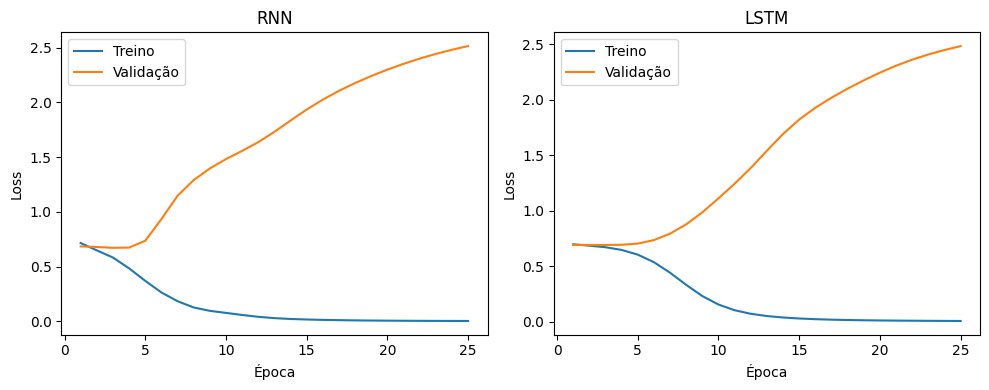

In [8]:
EPOCAS = 25
BATCH = 8
TAXA = 0.01
historicos = {}

for nome, modelo in [("RNN", modelo_rnn), ("LSTM", modelo_lstm)]:
    keras.utils.set_random_seed(42)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TAXA),
        loss="binary_crossentropy", metrics=["accuracy"]
    )
    historicos[nome] = modelo.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=EPOCAS, batch_size=BATCH, shuffle=False, verbose=0
    )
    h = historicos[nome].history
    print(f"{nome}: accuracy treino={h['accuracy'][-1]:.3f} | validação={h['val_accuracy'][-1]:.3f}")

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for eixo, nome in zip(eixos, ["RNN", "LSTM"]):
    h = historicos[nome].history
    epocas = np.arange(1, EPOCAS + 1)
    eixo.plot(epocas, h["loss"], label="Treino")
    eixo.plot(epocas, h["val_loss"], label="Validação")
    eixo.set(title=nome, xlabel="Época", ylabel="Loss")
    eixo.legend()
plt.tight_layout()
plt.show()


## Perguntas

**13.** Diferencie os hiperparâmetros T, d, H, épocas, batch e taxa de aprendizagem dos pesos e biases aprendidos.  
**14.** Compare as curvas. Há redução da perda? Há sinais de overfitting? Os resultados confirmam que um modelo com mais parâmetros sempre terá melhor validação?


# 7. Avaliação, previsões e estados aprendidos

O teste não foi usado para ajustar os pesos nem para selecionar configurações. Usaremos o limiar **0,5**: acima ou igual, positiva; abaixo, negativa.

**Este dataset é pequeno e contém frases curtas.** A comparação mostra diferenças de arquitetura, parâmetros e resultados desta execução; não demonstra superioridade geral da LSTM nem testa de forma controlada dependências de longo prazo. Não use o teste repetidamente para escolher hiperparâmetros.


In [9]:
print(f"{'Modelo':<8} {'Parâmetros':>12} {'Loss teste':>12} {'Accuracy':>10}")
resultados = {}
for nome, modelo in [("RNN", modelo_rnn), ("LSTM", modelo_lstm)]:
    perda, acuracia = modelo.evaluate(X_test, y_test, verbose=0)
    resultados[nome] = (perda, acuracia)
    print(f"{nome:<8} {modelo.count_params():>12} {perda:>12.4f} {acuracia:>10.3f}")

novos_textos = np.array([
    "produto bom", "produto não é bom",
    "gostei da compra", "não gostei da compra"
])
novos_ids = vectorizador(novos_textos).numpy()
prob_rnn = modelo_rnn.predict(novos_ids, verbose=0).ravel()
prob_lstm = modelo_lstm.predict(novos_ids, verbose=0).ravel()
print("\nProbabilidade de avaliação positiva:")
for texto, pr, pl in zip(novos_textos, prob_rnn, prob_lstm):
    print(f"RNN={pr:.3f} | LSTM={pl:.3f} | {texto}")

# Estados do classificador LSTM já treinado, para o mesmo documento.
h_aprendido, c_aprendido = modelo_estados(novos_ids[:1], training=False)
print("\nDocumento:", novos_textos[0])
print("h final:", np.round(h_aprendido[0].numpy(), 3))
print("c final:", np.round(c_aprendido[0].numpy(), 3))


Modelo     Parâmetros   Loss teste   Accuracy
RNN               333       2.7625      0.375
LSTM              645       2.9655      0.375

Probabilidade de avaliação positiva:
RNN=0.988 | LSTM=0.964 | produto bom
RNN=0.002 | LSTM=0.001 | produto não é bom
RNN=0.990 | LSTM=0.996 | gostei da compra
RNN=0.001 | LSTM=0.001 | não gostei da compra

Documento: produto bom
h final: [ 0.399 -0.17   0.265 -0.422  0.062 -0.374 -0.466 -0.304]
c final: [ 0.564 -0.316  0.42  -0.565  0.154 -0.518 -0.642 -0.452]


## Perguntas

**15.** Compare os resultados de teste e as previsões com e sem negação. Qual modelo foi melhor nesta execução? Por que isso não permite afirmar que ele será sempre melhor?  
**16.** Explique a principal diferença entre a RNN simples e a LSTM: como as portas permitem preservar informações ao longo de vários passos e como o erro supervisionado orienta esse aprendizado?
